In [135]:
library(ggplot2)
library(ggrepel)
library(plyr)
library(dplyr)
library(Seurat)
library(DescTools)
library(RColorBrewer)
library(forcats)
library(ggbeeswarm)
library(tidyR)

source("../sc_analysis_palettes_and_helpers.r")

setwd("/local/users/nfresma/repos/neuroblastoma_plasticity/human_nb_analysis/data/")
dat_name <- "hum_interPatient"


## Plot UMAPs and scores in heatmap

In [248]:
scores <- read.delim('aucell_scores.csv', stringsAsFactors = F, sep = ',', row.names = 1)
scores <- scores[scores$annotation_draft == 'Neuroendocrine',]

scores$cell_id <- rownames(scores)

In [249]:
umap_coord <- read.delim('X_umap_NB_only.csv', stringsAsFactors = F, sep = ',', row.names = 1)

umap_coord_harm <- read.delim('X_umap_harmony_NB_only.csv', stringsAsFactors = F, sep = ',', row.names = 1)
colnames(umap_coord_harm) <- paste0('harmony_', colnames(umap_coord_harm))

umap_coord$cell_id <- rownames(scores)
umap_coord_harm$cell_id <- rownames(scores)


In [250]:
table(rownames(scores) %in% rownames(umap_coord_harm))
table(rownames(umap_coord_harm) %in% rownames(scores))
table(rownames(umap_coord) %in% rownames(umap_coord_harm))


  TRUE 
141272 


  TRUE 
141272 


  TRUE 
141272 

In [251]:
# Merge scores and UMAP coordinates
scores_umap <- left_join(scores, umap_coord, by = 'cell_id')
scores_umap <- left_join(scores_umap, umap_coord_harm, by = 'cell_id')
rownames(scores_umap) <- scores_umap$cell_id

# Make sure sample names follow same notation here and in metadata
scores_umap$Sample_Name <- gsub('-','_',scores_umap$Sample_Name)

In [252]:
# Merge with metadata
metadata <- read.delim('metadata_processed_ready.csv',
                      sep = ',', stringsAsFactors = F, row.names = 1, header = T)

renaming_vec <- metadata$sample_name
names(renaming_vec) <- metadata$Patient


In [253]:
metadata$Sample_Name <- as.character(metadata$Sample_Name)
scores_umap$Sample_Name <- as.character(scores_umap$Sample_Name)

In [254]:
table(unique(metadata$sample_name)  %in% unique(scores$Sample_Name))
table(unique(scores_umap$Sample_Name)  %in% unique(metadata$sample_name))

metadata$Sample_Name <- metadata$sample_name


FALSE  TRUE 
  135    29 


TRUE 
  39 

In [255]:
# Add metadata
scores_umap_meta <- left_join(scores_umap, metadata, by = 'Sample_Name')
rownames(scores_umap) <- scores_umap$cell_id

##### Plot UMAPs

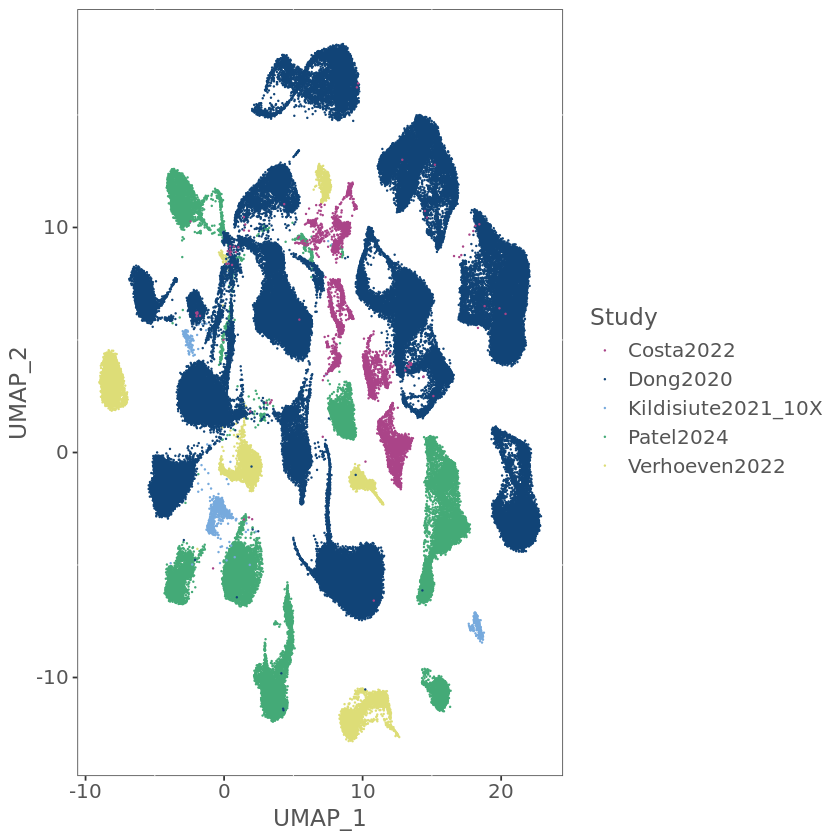

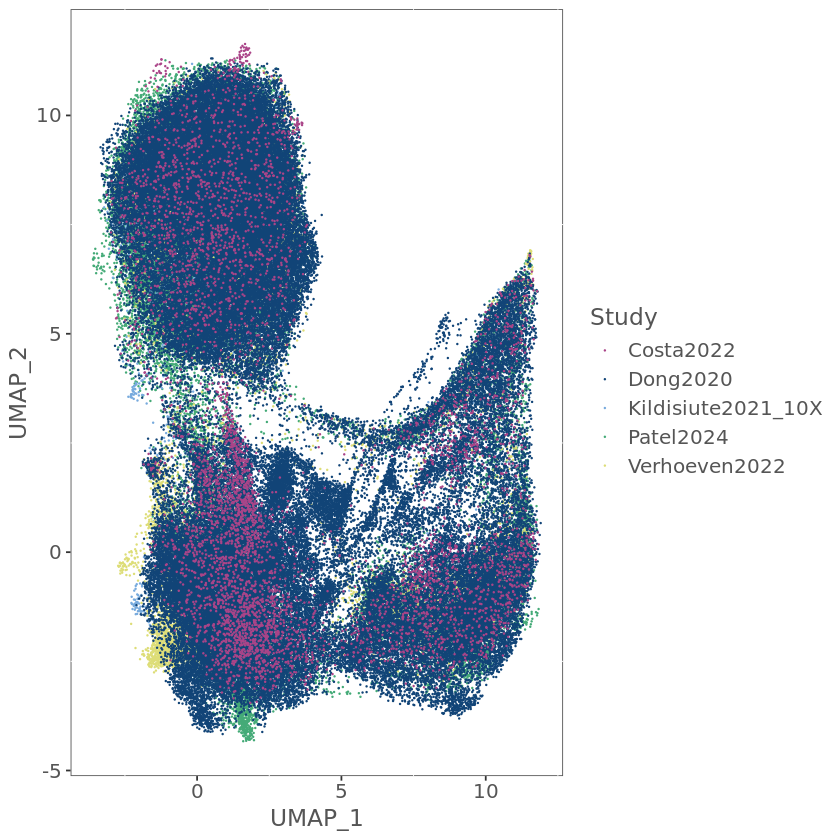

In [205]:
ploto <- ggplot(scores_umap_meta, aes(x = X0, y = X1, col = Study)) +
            geom_point(size = 0.05) +
            scale_color_manual(values = c(tol21rainbow[c(2,4,6,11,15)])) +
            xlab('UMAP_1') +
            ylab('UMAP_2') +
            mytheme_basic
ploto
ggsave(plot = ploto, filename = "pics/UMAP_scSamplesAll_Study_col.png", width = 6.3, height = 4, dpi = 500)


ploto <- ggplot(scores_umap_meta, aes(x = harmony_X0, y = harmony_X1, col = Study)) +
            geom_point(size = 0.05) +
            scale_color_manual(values = c(tol21rainbow[c(2,4,6,11,15)])) +
            xlab('UMAP_1') +
            ylab('UMAP_2') +
            mytheme_basic
ploto
ggsave(plot = ploto, filename = "pics/harmonUMAP_scSamplesAll_Study_col.png", width = 6.3, height = 4, dpi = 500)


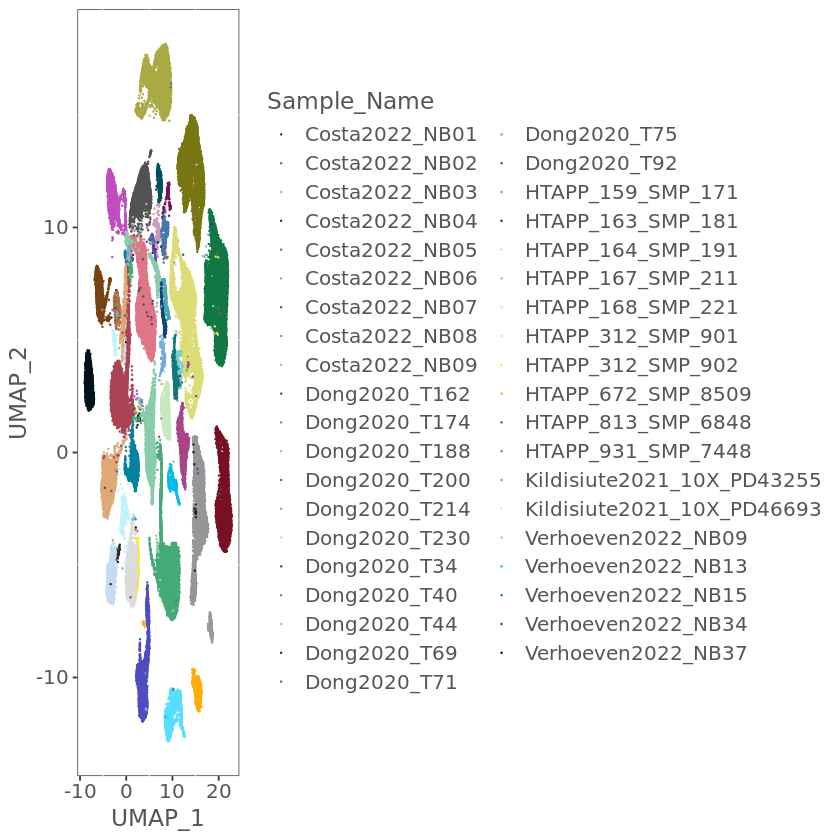

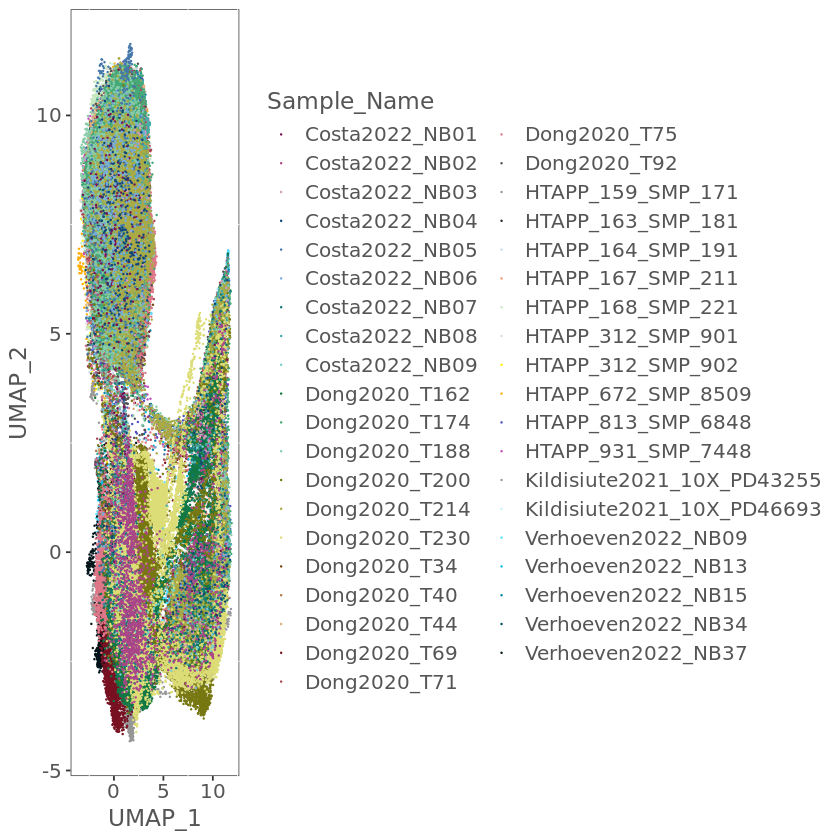

In [206]:
ploto <- ggplot(scores_umap_meta, aes(x = X0, y = X1, col = Sample_Name)) +
            geom_point(size = 0.05) +
        scale_color_manual(values = c(tol21rainbow, blues_24[c(4,8,12,16,20,24)])) +
        xlab('UMAP_1') +
        ylab('UMAP_2') +
        mytheme_basic
ploto
ggsave(plot = ploto, filename = "pics/UMAP_scSamplesAll_Sample_col.png", width = 9, height = 4, dpi = 500)


ploto <- ggplot(scores_umap_meta, aes(x = harmony_X0, y = harmony_X1, col = Sample_Name)) +
            geom_point(size = 0.05) +
        scale_color_manual(values = c(tol21rainbow, blues_24[c(4,8,12,16,20,24)])) +
        xlab('UMAP_1') +
        ylab('UMAP_2') +
        mytheme_basic
ploto
ggsave(plot = ploto, filename = "pics/harmonUMAP_scSamplesAll_Sample_col.png", width = 9, height = 4, dpi = 500)


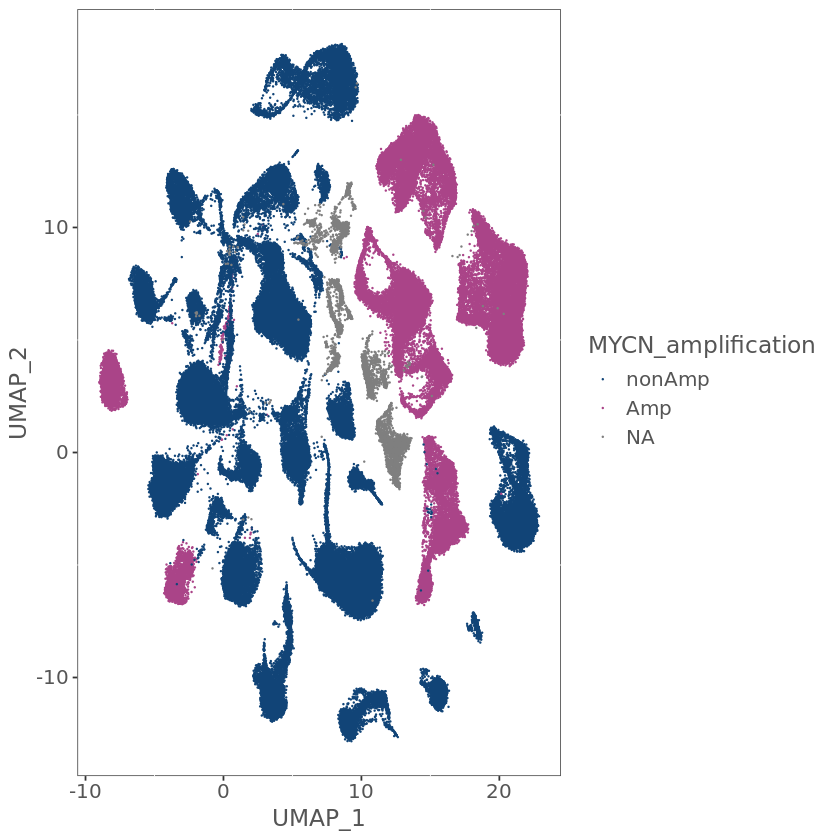

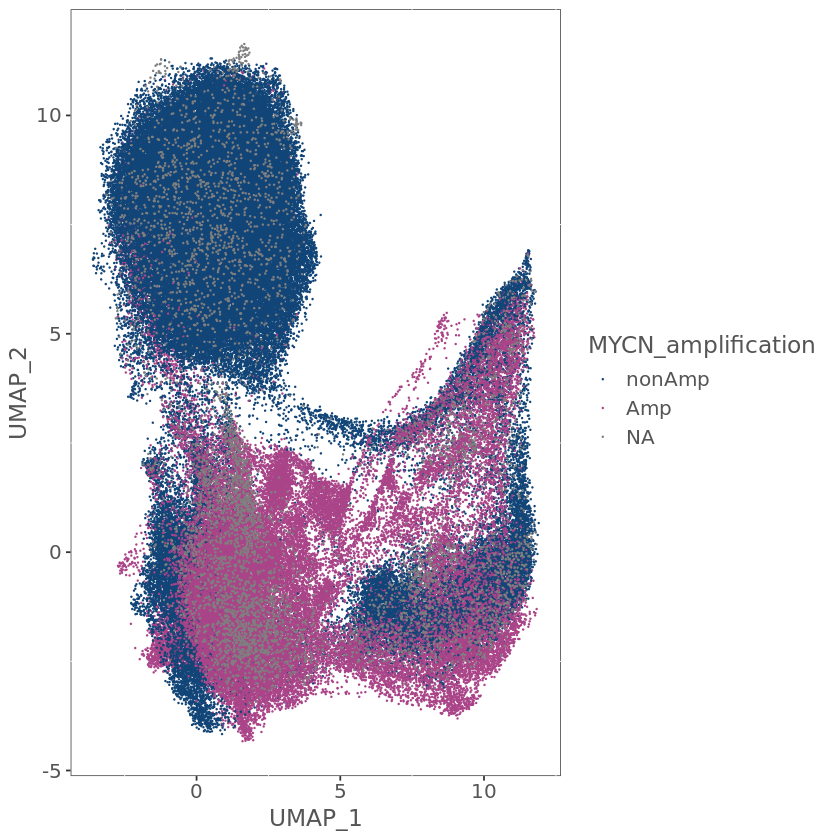

In [209]:
scores_umap_meta$MYCN_amplification <- factor(as.character(scores_umap_meta$MYCN_amplification), levels = c('nonAmp','Amp','unkown'))

ploto <- ggplot(scores_umap_meta, aes(x = X0, y = X1, col = MYCN_amplification)) +
            geom_point(size = 0.05) +
            scale_color_manual(values = c(tol21rainbow[c(4,2)], 'grey')) +
            xlab('UMAP_1') +
            ylab('UMAP_2') +
            mytheme_basic

ploto
ggsave(plot = ploto, filename = "pics/UMAP_scSamplesAll_MYCN_col.png", width = 6.35, height = 4, dpi = 500)


ploto <- ggplot(scores_umap_meta, aes(x = harmony_X0, y = harmony_X1, col = MYCN_amplification)) +
            geom_point(size = 0.05) +
            scale_color_manual(values = c(tol21rainbow[c(4,2)], 'grey')) +
        xlab('UMAP_1') +
        ylab('UMAP_2') +
        mytheme_basic
ploto
ggsave(plot = ploto, filename = "pics/harmonUMAP_scSamplesAll_MYCN_col.png", width = 6.35, height = 4, dpi = 500)


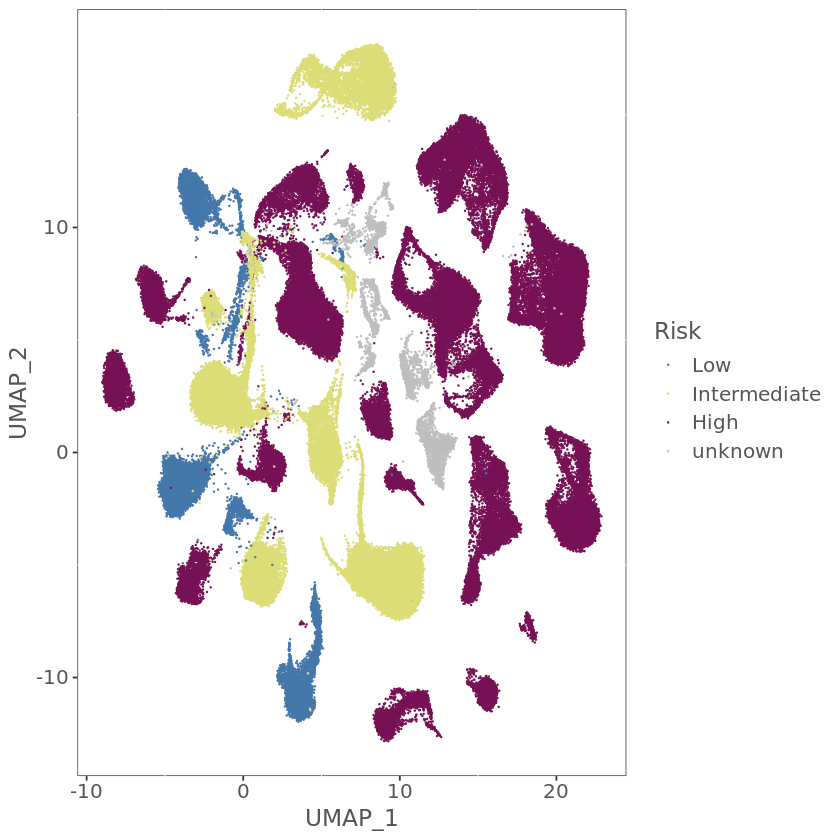

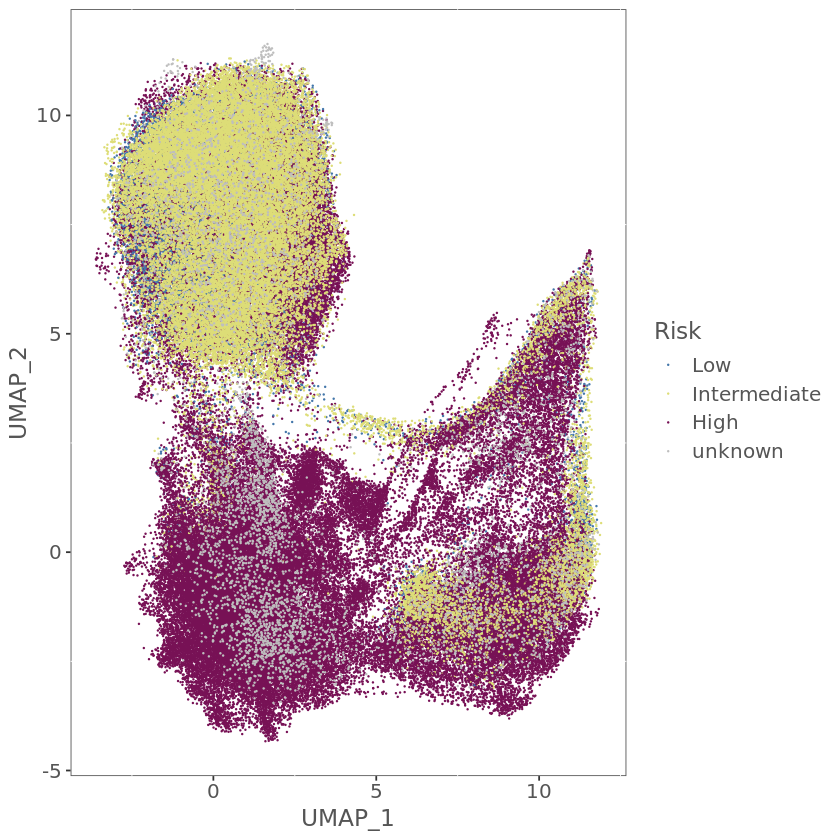

In [211]:
scores_umap_meta$Risk <- factor(as.character(scores_umap_meta$Risk), levels = c('Low','Intermediate','High','unknown'))

ploto <- ggplot(scores_umap_meta, aes(x = X0, y = X1, col = Risk)) +
            geom_point(size = 0.05) +
        scale_color_manual(values = c(tol21rainbow[c(5,15,1)],'grey')) +
        xlab('UMAP_1') +
        ylab('UMAP_2') +
        mytheme_basic

ploto
ggsave(plot = ploto, filename = "pics/UMAP_scSamplesAll_Risk_col.png", width = 6.3, height = 4, dpi = 500)


ploto <- ggplot(scores_umap_meta, aes(x = harmony_X0, y = harmony_X1, col = Risk)) +
            geom_point(size = 0.05) +
        scale_color_manual(values = c(tol21rainbow[c(5,15,1)],'grey')) +
        xlab('UMAP_1') +
        ylab('UMAP_2') +
        mytheme_basic
ploto
ggsave(plot = ploto, filename = "pics/harmonUMAP_scSamplesAll_Risk_col.png", width = 6.3, height = 4, dpi = 500)


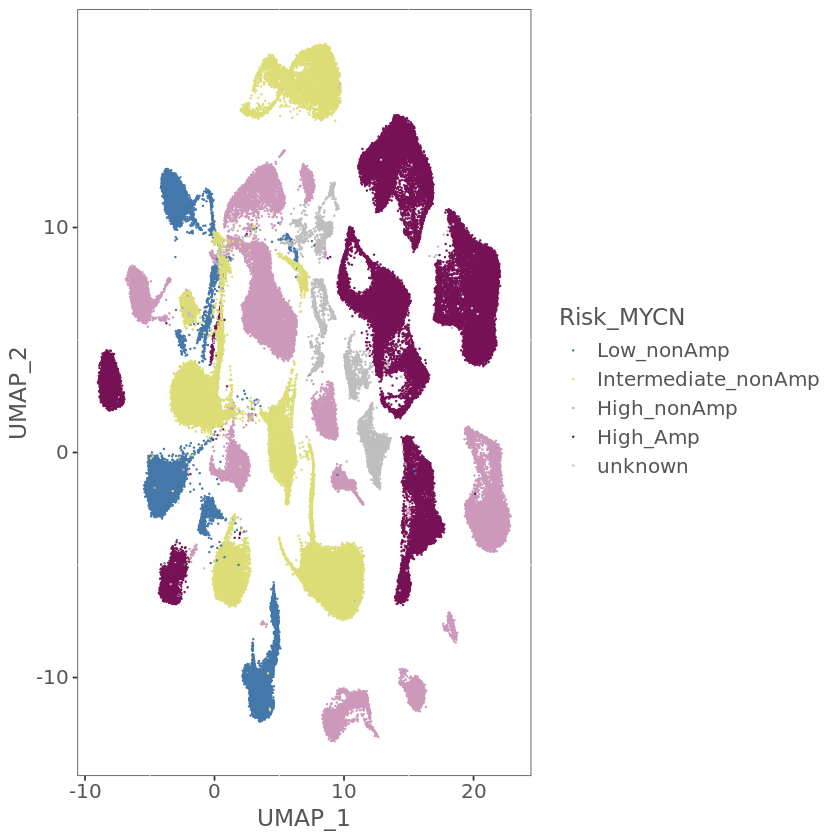

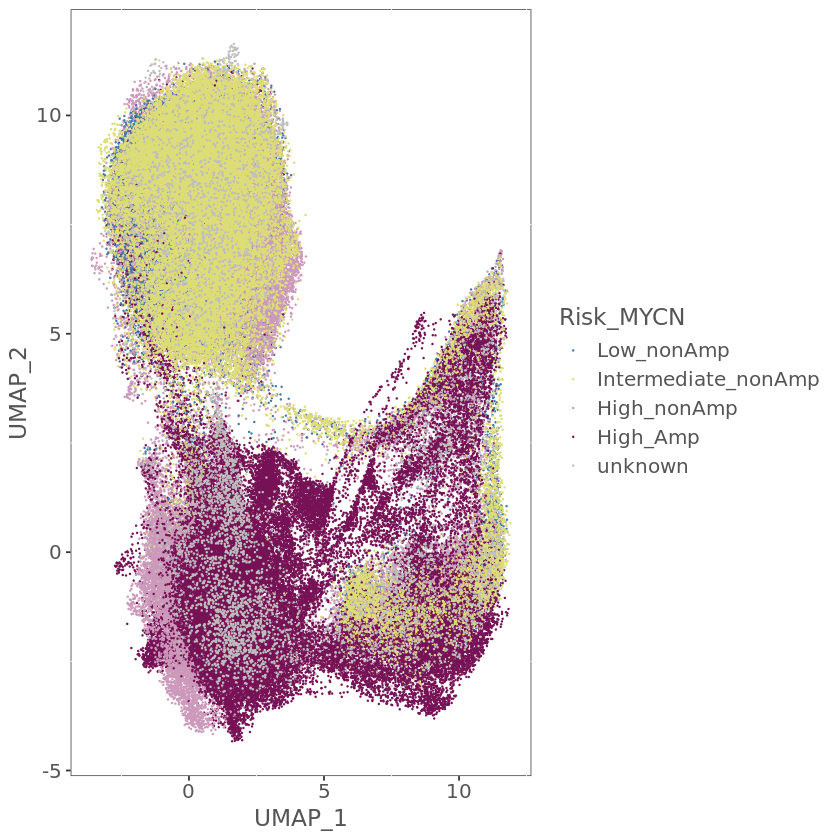

In [212]:
scores_umap_meta$Risk_MYCN <- factor(as.character(scores_umap_meta$Risk_MYCN), levels = c('Low_nonAmp','Intermediate_nonAmp','High_nonAmp','High_Amp','unknown'))

ploto <- ggplot(scores_umap_meta, aes(x = X0, y = X1, col = Risk_MYCN)) +
            geom_point(size = 0.05) +
            scale_color_manual(values = c(tol21rainbow[c(5,15,3,1)],'grey')) +
            xlab('UMAP_1') +
            ylab('UMAP_2') +
            mytheme_basic


ploto
ggsave(plot = ploto, filename = "pics/UMAP_scSamplesAll_RiskMYCN_col.png", width = 6.5, height = 4, dpi = 500)


ploto <- ggplot(scores_umap_meta, aes(x = harmony_X0, y = harmony_X1, col = Risk_MYCN)) +
            geom_point(size = 0.05) +
            scale_color_manual(values = c(tol21rainbow[c(5,15,3,1)],'grey')) +
        xlab('UMAP_1') +
        ylab('UMAP_2') +
        mytheme_basic
ploto
ggsave(plot = ploto, filename = "pics/harmonUMAP_scSamplesAll_RiskMYCN_col.png", width = 6.5, height = 4, dpi = 500)


##### Plot module expression heatmaps

In [264]:
mods_all <- colnames(scores)[!colnames(scores) %in% c('annotation_draft','cell_id','Sample_Name')]

scores_umap_meta$Risk_MYCN <- as.character(scores_umap_meta$Risk_MYCN)

In [265]:
scores_umap_meta$Risk_MYCN <- as.character(scores_umap_meta$Risk_MYCN)

for(i in 1:length(mods_all)){
    mod_it <- mods_all[i]

    metasub <- scores_umap_meta
    colnames(metasub)[colnames(metasub) == mod_it] <- 'mod_it'

    result <- aggregate(mod_it ~ Risk_MYCN, data = metasub, FUN = median)
    colnames(result) <- c('Risk_MYCN',mod_it)

    if(i == 1){
        result_all <- result
    }else{
        result_all <- left_join(result_all, result, by = 'Risk_MYCN')
    }
}

In [266]:

result_all_long <- pivot_longer(result_all,
                        cols = -Risk_MYCN,           # Exclude the 'risk-ID column
                        names_to = "module",
                        values_to = "expression_score") 

# View the transformed data frame
result_all_long <- as.data.frame(result_all_long)

png 
  2

null device 
          1

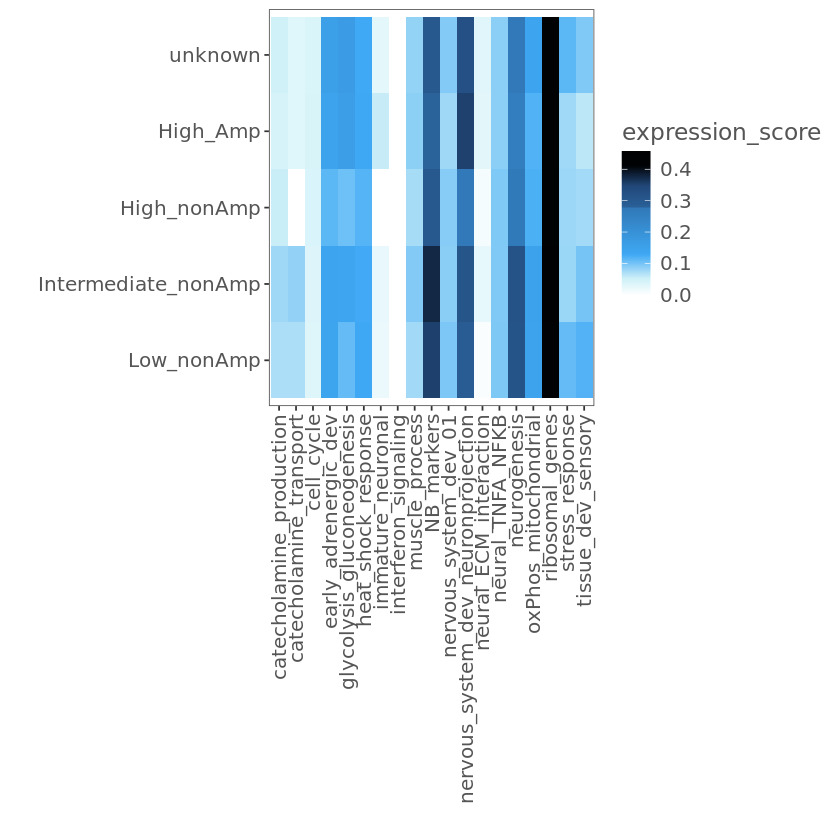

In [267]:
bk0 <- c(seq(0,0.12,by=0.01))
bk1 <- c(seq(0.1201,0.61,by=0.005))
bk2 <- c(seq(0.61+0.001,max(result_all_long$expression_score)+0.45,by=0.005))
bk <- c(bk0,bk1,bk2)  #combine the break limits for purpose of graphing
bk[length(bk)] <- 1.2
my_palette <- c(colorRampPalette(colors = c("white","#caf0f8"))(n = length(bk0)),
                colorRampPalette(colors = c("#caeef8",'#3fa9f5','#3891d6',"#3179b8"))(n = length(bk1)),
                colorRampPalette(colors = c("#2a6199","#22487a","black"))(n = length(bk2)))


result_all_long$Risk_MYCN <- factor(as.character(result_all_long$Risk_MYCN), levels = c('Low_nonAmp','Intermediate_nonAmp','High_nonAmp','High_Amp','unknown'))


ggplot(result_all_long, aes(module, Risk_MYCN, fill= expression_score)) + 
  geom_tile() +
  labs(x = '', y = '' ) +
  scale_fill_gradientn(colours = my_palette,
                       values = bk) +
  mytheme_angledX


pdf("pics/Heatmap_allDRmods_singleCellHumSets_NBonly_mean_AUCScores.pdf", width = 7.5, height = 4.5)
print(
    ggplot(result_all_long, aes(module, Risk_MYCN, fill= expression_score)) + 
      geom_tile() +
      labs(x = '', y = '' ) +
      scale_fill_gradientn(colours = my_palette,
                           values = bk) +
      mytheme_angledX
)
dev.off()
dev.off()

In [280]:
### calculate mean and median per sample

summary_df <- scores_umap_meta %>%
  group_by(sample_name, Risk_MYCN) %>%
  summarise(
    across(
      all_of(mods_all),
      list(
        mean = ~mean(.x, na.rm = TRUE),
        median = ~median(.x, na.rm = TRUE)
      ),
      .names = "{.col}_{.fn}"
    ),
    .groups = "drop"
  )

In [291]:
# get median summary
library(tidyr)

median_long <- summary_df %>%
  pivot_longer(
    cols = ends_with("_median"),
    names_to = "Factor",
    values_to = "Median"
  ) %>%
  mutate(
    Factor = sub("_median", "", Factor)
  )

median_long <- median_long[median_long$Risk_MYCN != 'unknown',]
median_long <- median_long[,c('sample_name','Risk_MYCN','Factor','Median')]

In [299]:
write.csv(median_long, '../source_data_figs/source_data_s6e.csv', quote = F)

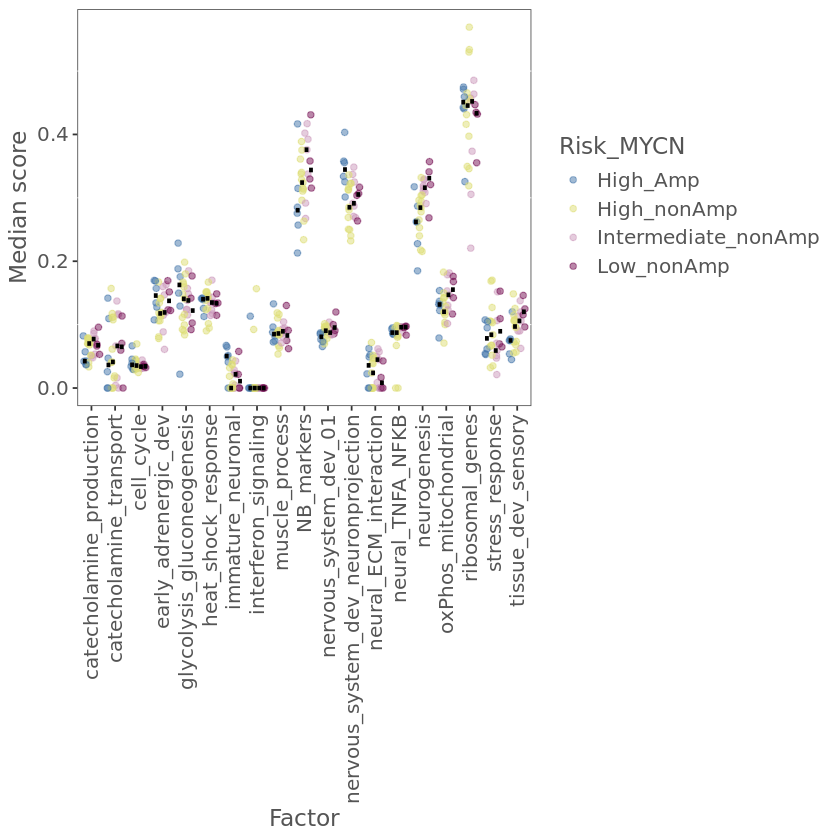

In [293]:
# Plot median

dodge_width <- 0.75  # shared width for jitter + median

ggplot(median_long, aes(x = Factor,
           y = Median)) +
  geom_point(
      aes(color = Risk_MYCN),
    position = position_jitterdodge(
      jitter.width = 0.15,
      dodge.width = dodge_width
    ),
    alpha = 0.5
  ) +
  stat_summary(
    fun = median,
    geom = "crossbar",
    aes(group = Risk_MYCN),
    position = position_dodge(width = dodge_width),
    width = 0.65,      # length of the median line within each dodge slot
    fatten = 1,        # keep line thin/normal, not exaggerated
    linewidth = 1.3
  ) +
    scale_fill_manual(values = c(tol21rainbow[c(5,15,3,1)],'grey')) +
    scale_color_manual(values = c(tol21rainbow[c(5,15,3,1)],'grey')) +
  labs(
    x = "Factor",
    y = "Median score"
  ) +
    mytheme_angledX

In [294]:

pdf("pics/Boxplot_allDRmods_mediansPerSamplePerGroup_AUCScores.pdf", width = 13, height = 5.5)
print(
    ggplot(median_long, aes(x = Factor,
           y = Median)) +
  geom_point(
      aes(color = Risk_MYCN),
    position = position_jitterdodge(
      jitter.width = 0.15,
      dodge.width = dodge_width
    ),
    size = 0.9,
    alpha = 0.8
  ) +
  stat_summary(
    fun = median,
    geom = "crossbar",
    aes(group = Risk_MYCN),
    position = position_dodge(width = dodge_width),
    width = 0.65,      # length of the median line within each dodge slot
    fatten = 1,        # keep line thin/normal, not exaggerated
    linewidth = 1.3
  ) +
    scale_fill_manual(values = c(tol21rainbow[c(5,15,3,1)],'grey')) +
    scale_color_manual(values = c(tol21rainbow[c(5,15,3,1)],'grey')) +
  labs(
    x = "Factor",
    y = "Median score"
  ) +
    mytheme_angledX
)
dev.off()
dev.off()

png 
  2

null device 
          1

In [295]:
dev.off()
dev.off()
dev.off()
dev.off()

null device 
          1

null device 
          1

null device 
          1

null device 
          1

# Plotting inter-tumor expression difference and intra-tumor expression variance

In [307]:
type <- 'auc' # tirosh, barkley, auc or metafeatures

# set expression cut-off
filt_type <- 'all'
#filt_type <- 0.05 # Set minimum fraction of cells of a clone in which module has to be activated to keep comparison

# set score type (this is always AUC here)
score_type <- 'auc'

# reload results
results_df_p_all_ann <- read.delim('resultPlusAUCbasedStats_allSNsamples.csv',
                      sep = ';', stringsAsFactors = F, header = T, row.names = 1)

# Filter comparisons according to desired minimum expression fractions
if(filt_type == 'all'){

    filt_name <- 'all_comps'

}else{
    
    filt_name <- paste0('comps_over_',paste0(filt_type*100),'_pct')
    
    results_df_p_all_ann$pct_expr_max <- apply(results_df_p_all_ann[,c('pct_expr_clone1','pct_expr_clone2')], 1, max)
    results_df_p_all_ann <- results_df_p_all_ann[results_df_p_all_ann$pct_expr_max >= filt_type,]
    results_df_p_all_ann$pct_expr_max <- NULL
}
    

In [308]:
# Get -log10(pval)
# First set a dummy value for very low p-values
results_df_p_all_ann$p_val_perm_plus <- results_df_p_all_ann$empirical_pval + (1/1000)
# Set maximum p back to 1
results_df_p_all_ann$p_val_perm_plus[ results_df_p_all_ann$p_val_perm_plus>1 ] <- 1

# Calculate -log10(pval)
results_df_p_all_ann$neglog10pval <- -log10(results_df_p_all_ann$p_val_perm_plus)

# Set significance column
results_df_p_all_ann$sig <- '>= 0.05'
results_df_p_all_ann$sig[results_df_p_all_ann$empirical_pval < 0.05] <- '< 0.05'

In [309]:
# Set and rename modules

module_metnames <- colnames(scores)[!colnames(scores) %in% c('Sample_Name','annotation_draft')]
module_metnames <- gsub('nervous_system_dev_neuronprojection','neuron_projection',module_metnames)
module_metnames <- gsub('nervous_system_dev_01','nervous_system_dev',module_metnames)


results_df_p_all_ann$module <- gsub('nervous_system_dev_neuronprojection','neuron_projection',results_df_p_all_ann$module)
results_df_p_all_ann$module  <- gsub('nervous_system_dev_01','nervous_system_dev',results_df_p_all_ann$module)



In [310]:
# Load final module names to translate previous names consistently throughout the code
module_renaming_df <- read.delim('/local/users/nfresma/final_module_names.csv', sep = ';',header = T)
module_renaming_df$new_name[module_renaming_df$new_name == 'nervous_system_dev_neuronprojection'] <- 'neuron_projection'
module_renaming_df$new_name[module_renaming_df$new_name == 'nervous_system_dev_01'] <- 'nervous_system_dev'

module_renaming_vec <- module_renaming_df$new_name
names(module_renaming_vec) <- module_renaming_df$old_name

module_renaming_df_keep <- module_renaming_df[module_renaming_df$to_keep == 'yes',]

In [311]:
# FIlter modules
# If you filter, set this variable:
mod_filtered_var <- '_filteredMods'

results_df_p_all_ann <- results_df_p_all_ann[results_df_p_all_ann$module %in% module_renaming_df_keep$new_name,]

mod_type_vals <- as.data.frame(c(
    catecholamine_production = 'symp_specific',
    catecholamine_transport= 'symp_specific',
    cell_cycle= 'phys_state',
    early_adrenergic_dev = 'symp_specific',
    glycolysis_gluconeogenesis = 'phys_state',
    heat_shock_response = 'phys_state',
    immature_neuronal = 'symp_specific',
    interferon_signaling = 'phys_state',
    muscle_process = 'symp_specific',
    NB_markers = 'symp_specific',
    nervous_system_dev = 'symp_specific',
    neuron_projection = 'symp_specific',
    neural_ECM_interaction = 'symp_specific',
    neural_TNFA_NFKB = 'symp_specific',
    neurogenesis = 'symp_specific',
    oxPhos_mitochondrial = 'phys_state',
    ribosomal_genes = 'phys_state',
    stress_response = 'phys_state',
    tissue_dev_sensory = 'symp_specific'
))

mod_type_vals$module <- rownames(mod_type_vals)
colnames(mod_type_vals) <- c('type','module')

### For intra-dataset

In [312]:
## Add a column for the average pct expressed in both patients
results_df_p_all_ann$pct_expr_clone_mean <- (results_df_p_all_ann$pct_expr_clone1 + results_df_p_all_ann$pct_expr_clone2)/2

## Module sets
set_1 <- unique(results_df_p_all_ann$module)

In [313]:
# Subset to plot
# SET SUBSET TO PLOT HERE - we only take comparisons within a dataset
dataset_type <- c('intra_dataset')
set <- set_1
set_name <- 'Set_1'

type_name <- paste(type, collapse = '_')

results_df_p_all_plot <- results_df_p_all_ann[results_df_p_all_ann$Study_1 == results_df_p_all_ann$Study_2,]
results_df_p_all_plot <- results_df_p_all_plot[results_df_p_all_plot$module %in% set,]
results_df_p_all_plot$diff <- results_df_p_all_plot$abs_real_logFC / results_df_p_all_plot$mean_perm_logFC
results_df_p_all_plot$diff[results_df_p_all_plot$abs_real_logFC == 0 | results_df_p_all_plot$mean_perm_logFC == 0] <- 0

In [317]:
# save median and mean difference scores
results_df_p_all_short <- results_df_p_all_plot[,c('module','diff')]

df_median <- results_df_p_all_short %>%
  group_by(module) %>%
  summarise(median_diff = median(diff))

df_mean <- results_df_p_all_short %>%
  group_by(module) %>%
  summarise(mean_diff = mean(diff))


df_stats <- left_join(df_median,df_mean, by = 'module')

write.csv(df_stats, paste0('mean_and_median_interPatient_diffScores_',score_type,'_AUCfiltered_',filt_name,'.csv'), quote = F)

png 
  2

null device 
          1

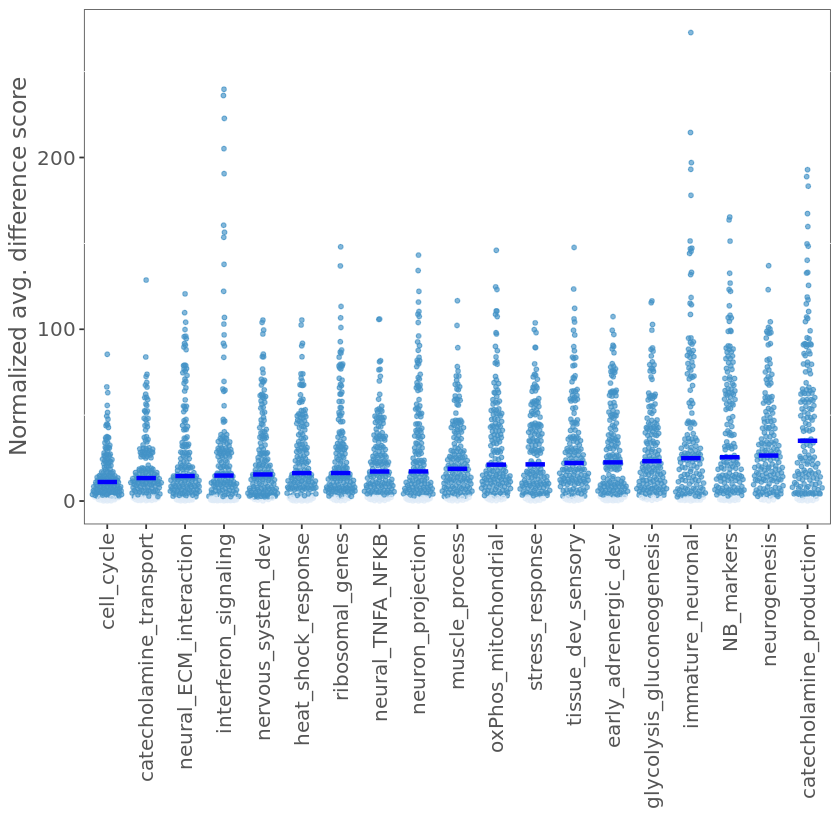

In [316]:
results_df_p_all_plot <- results_df_p_all_plot %>% mutate(module = fct_reorder(module, diff, .fun='median'))

     ggplot(results_df_p_all_plot, aes(x = module, y = diff)) +
                geom_quasirandom(aes(color = sig, group = 1),alpha = 0.65,dodge.width = 0.4, size = 1) +
                scale_color_manual(values = c('#4292C6','#DEEBF7')) +
                stat_summary(fun = median, geom = "crossbar",
                             width = .5, color = "blue") +
                labs(x = '', y = 'Normalized avg. difference score') +
                theme(legend.position = 'none') +
                mytheme_angledX

pdf(paste0("pics/InterPatientIntraDataset_PerModuleValues_scoreType_",score_type,"_AUCfiltered_",filt_name,"_AvgDiffScore_",mod_filtered_var,".pdf"), width = 5.4, height = 4.3)
        print(
            ggplot(results_df_p_all_plot, aes(x = module, y = diff)) +
                geom_quasirandom(aes(color = sig, group = 1),alpha = 0.65,dodge.width = 0.4, size = 1) +
                scale_color_manual(values = c('#4292C6','#DEEBF7')) +
                stat_summary(fun = median, geom = "crossbar",
                             width = .5, color = "blue") +
                labs(x = '', y = 'Normalized avg. difference score') +
                theme(legend.position = 'none') +
                mytheme_angledX
        )
dev.off()   
dev.off()    


In [318]:
# save source data
write.csv(results_df_p_all_plot, '/local/users/nfresma/repos/neuroblastoma_plasticity/human_nb_analysis/source_data_figs/source_data_4h.csv', quote = F)


#### p-value plots

png 
  2

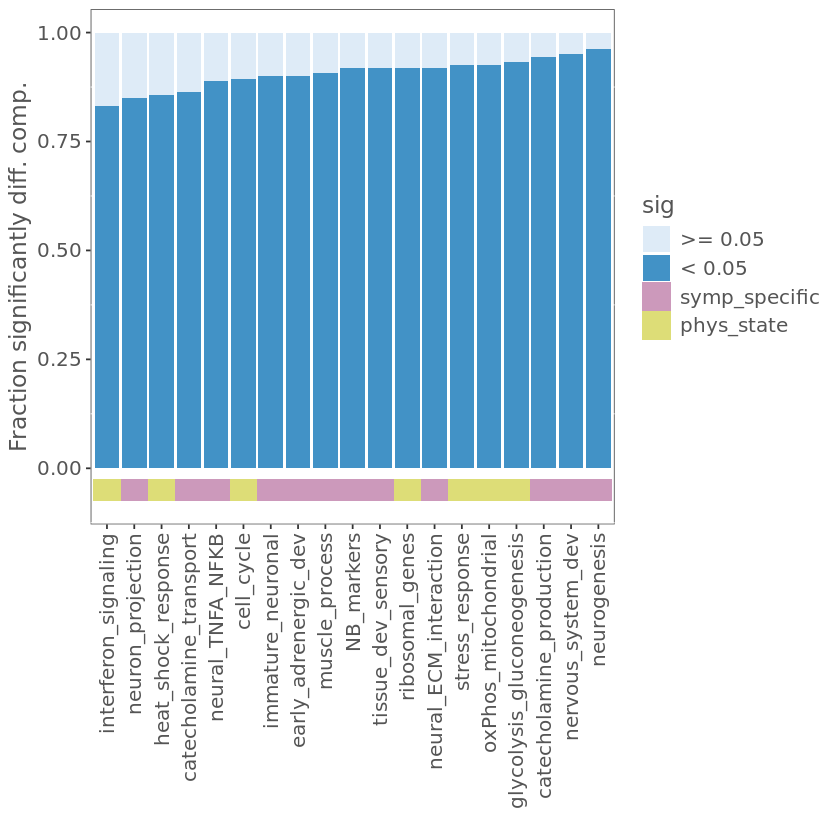

In [319]:
# Plot fraction significant / non-significant bar plots

test <- as.data.frame(table(results_df_p_all_plot$module, results_df_p_all_plot$sig))
colnames(test) <- c('module', 'sig','fraction')
#test <- test[order(test$fraction, decreasing = T),]
test <- test[with(test, order(sig, fraction)), ]

# Calculate the total fraction for each module
test <- test %>%
  group_by(module) %>%
  mutate(total_fraction = sum(fraction)) %>%
  ungroup()

# Calculate the fraction of each fraction value per sig value for each module
test <- test %>%
  mutate(fraction_of_total = fraction / total_fraction)

test <- left_join(test, mod_type_vals, by = 'module')

test$sig <- factor(as.character(test$sig), levels = c('>= 0.05','< 0.05'))
test <- test[with(test, order(sig,fraction_of_total)), ]
test$module <- factor(as.character(test$module), levels = rev(unique(test$module)))

test$type <- factor(as.character(test$type), levels = c('symp_specific','phys_state'))


ploto <- ggplot(test, aes(fill=sig, y=fraction, x=module)) + 
            geom_bar(position="fill", stat="identity") +
            scale_fill_manual(values = c("#DEEBF7","#4292C6",'#CC99BB','#DDDD77')) +
            labs(x = '', y = 'Fraction significantly diff. comp.') +
            geom_tile(aes(x=module, y=-0.05, fill=type), height=0.05) +
            mytheme_angledX

ggsave(plot = ploto, filename = paste0("pics/InterPatientIntraDataset_PerModuleValues_scoreType_",score_type,"_",filt_name,"_FractionSigBarplot",mod_filtered_var,".png"), width = 7, height = 6.5, dpi = 500)

ploto


pdf(paste0("pics/InterPatientIntraDataset_PerModuleValues_scoreType_",score_type,"_",filt_name,"_FractionSigBarplot",mod_filtered_var,".pdf"), width = 5.8, height = 4.5)
        print(
            ggplot(test, aes(fill=sig, y=fraction, x=module)) + 
                geom_bar(position="fill", stat="identity") +
                scale_fill_manual(values = c("#DEEBF7","#4292C6",'#CC99BB','#DDDD77')) +
                labs(x = '', y = 'Fraction significantly diff. comp.') +
                geom_tile(aes(x=module, y=-0.05, fill=type), height=0.05) +
                mytheme_angledX
        )
dev.off()     
    

In [320]:
dev.off()     
dev.off()     
dev.off()     

null device 
          1

null device 
          1

null device 
          1

In [321]:
# write to table
test <- test[test$sig == '< 0.05',]
write.csv(test, paste0('fractionSigComps_interPatient_',score_type,'_AUCfiltered_',filt_name,'.csv'), quote = F)

# Load intra-clone variance results

In [322]:
intravar_patient_results <- read.delim('all_hvg_results_genes_and_programs.csv',
                      sep = ',', stringsAsFactors = F, header = T)


In [323]:
# get module names to keep
scores <- read.delim('aucell_scores.csv', stringsAsFactors = F, sep = ',', row.names = 1)
module_metnames <- colnames(scores)[!colnames(scores) %in% c('Sample_Name','annotation_draft')]


In [324]:
intravar_patient_results$gene <- gsub('_NB_cells_raw_sum','',intravar_patient_results$gene)
intravar_patient_results <- intravar_patient_results[intravar_patient_results$gene %in% module_metnames,]


In [326]:
# Load and add metadata
metadata <- read.delim('metadata_processed_ready.csv',
                      sep = ',', stringsAsFactors = F, row.names = 1, header = T)
metadata$sample_name <- rownames(metadata)
renaming_vec <- metadata$sample_name
names(renaming_vec) <- metadata$Patient

metadata <- metadata[metadata$Assay == 'cell',]
# There is one 'duplicate' patient, with a sample before and one after treatment.
# Unfortunately the Patient-level annotation seems to have been used and not the samples for this analysis.
# So we'll have to make due with the mixed Patient sample
# We label patients with ONLY untreated samples beforehand so that we can filter for them later

untreatedPat <- metadata$Patient[metadata$Treatment_Status == 'untreated']
treatedPat <- metadata$Patient[metadata$Treatment_Status == 'treated']
trueUntreatedPat <- untreatedPat[!untreatedPat %in% treatedPat]

metadata$finalPatTreatStat <- metadata$Treatment_Status
metadata$finalPatTreatStat[metadata$Patient %in% trueUntreatedPat] <- 'untreated'
metadata <- metadata[!duplicated(metadata$Patient),]

metadata <- metadata[,c('Patient',
                        'Platform',
                        'Response',
                        'Risk',
                        'Assay',
                        'Age',
                        'Age_in_months',
                        'COG_Risk',
                        'Cell_condition',
                        'Ethnicity',
                        'Follow_up',
                        'Gender',
                        'Histologic_Diagnosis',
                        'ALK_mutation',
                        'INSS_Stage',
                        'MYCN_amplification',
                        'Risk',
                        'Sample',
                        'Sample_Site',
                        'Sample_Type',
                        'TP53_Status',
                        'Treatment_Status',
                        'Treatment_Type',
                        'Study',
                        'sample_name',
                        'finalPatTreatStat')]

In [328]:
intravar_patient_ext <- left_join(intravar_patient_results, metadata, by = 'Patient')

#### Add stats

In [330]:
# Load and add expression stats
type <- 'auc' 

results_stats_df <- read.delim(paste0('expr_stats_samplepairs_modType_',type,'.csv'), stringsAsFactors = T, sep = ',', row.names = 1)

In [331]:
results_stats_df_1 <- results_stats_df[,colnames(results_stats_df) %like any% c('%1','%ule')]
colnames(results_stats_df_1) <- gsub('1','',colnames(results_stats_df_1))

results_stats_df_2 <- results_stats_df[,colnames(results_stats_df) %like any% c('%2','%ule')]
colnames(results_stats_df_2) <- gsub('2','',colnames(results_stats_df_2))

results_stats_df_singpat <- rbind(results_stats_df_1, results_stats_df_2)
results_stats_df_singpat$patmod <- paste0(results_stats_df_singpat$Clone, results_stats_df_singpat$Module)
results_stats_df_singpat <- results_stats_df_singpat[!duplicated(results_stats_df_singpat$patmod),]
#results_stats_df_singpat$Clone <- NULL
#results_stats_df_singpat$Module <- NULL

In [332]:
intravar_patient_ext$patmod <- paste0(intravar_patient_ext$sample_name, intravar_patient_ext$gene)

In [333]:
intravar_patient_ext_ext <- left_join(intravar_patient_ext, results_stats_df_singpat, by = 'patmod')

In [334]:
## Save
write.table(intravar_patient_ext_ext, 'modVarsResults_allPatients_withMetaAndStats.csv', quote = F, sep = ';')

## Re-load data for plotting

In [360]:
intravar_patient_ext_ext <- read.delim('modVarsResults_allPatients_withMetaAndStats.csv', stringsAsFactors = F, sep = ';')
intravar_patient_ext_ext$Module <- gsub('nervous_system_dev_neuronprojection','neuron_projection',intravar_patient_ext_ext$Module)
intravar_patient_ext_ext$Module <- gsub('nervous_system_dev_01','nervous_system_dev',intravar_patient_ext_ext$Module)

In [361]:
filt_type <- 'all'
#filt_type <- '0.05' # Set minimum fraction of cells of a clone in which module has to be activated to keep comparison

# Filter if desired
dim(intravar_patient_ext_ext)
if(filt_type == 'all'){
    
    perTumVar_plot <- intravar_patient_ext_ext
    
}else{

    perTumVar_plot <- intravar_patient_ext_ext[intravar_patient_ext_ext$pct_expr_clone >= filt_type,]
    
}

dim(perTumVar_plot)

perTumVar_plot <- perTumVar_plot[!is.na(perTumVar_plot$variances_norm),]



[1] 703  38

[1] 703  38

In [362]:
treat_filt <- 'all'
#treat_filt <- 'untreated'

# Filter if desired
dim(perTumVar_plot)
if(treat_filt == 'all'){
    
    perTumVar_plot <- perTumVar_plot
    
}else{

    perTumVar_plot <- perTumVar_plot[!is.na(perTumVar_plot$finalPatTreatStat) & perTumVar_plot$finalPatTreatStat == treat_filt,]
    
}

dim(perTumVar_plot)



[1] 703  38

[1] 703  38

png 
  2

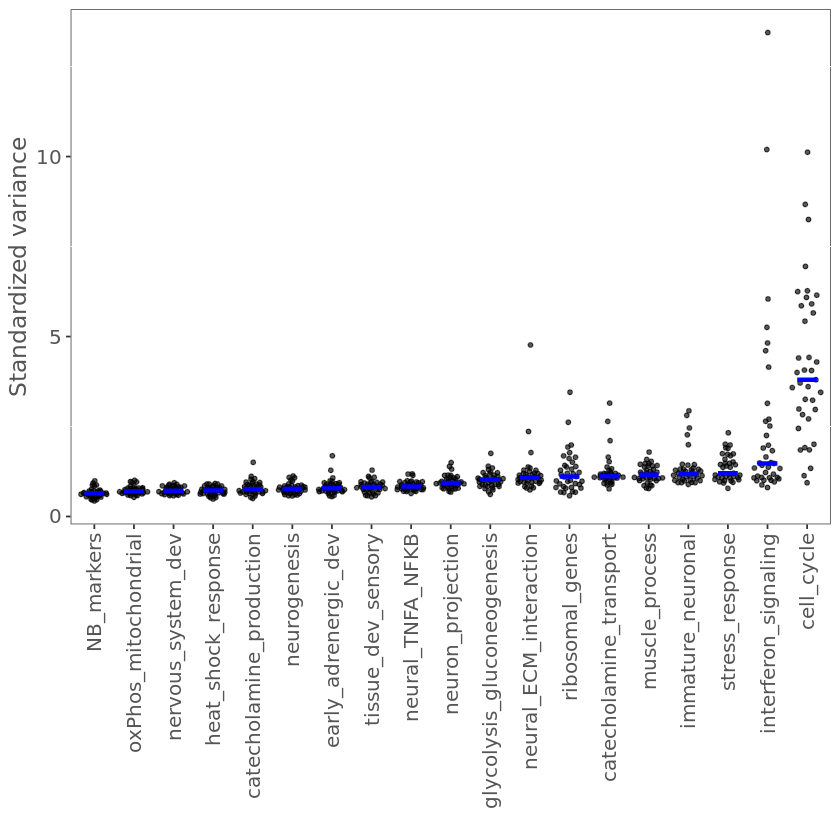

In [363]:
perTumVar_plot <- perTumVar_plot %>% mutate(Module = fct_reorder(Module, variances_norm, .fun='median'))

ploto <- ggplot(perTumVar_plot, aes(x = Module, y = variances_norm)) +
            geom_quasirandom(alpha = 0.65,dodge.width = 0.4, size = 1) +
            stat_summary(fun = median, geom = "crossbar",
                         width = .5, color = "blue") +
            labs(x = '', y = 'Standardized variance') +
            mytheme_angledX
ploto

ggsave(plot = ploto, filename = paste0("pics/VST_perModule_perPatient_Jitter_",type,"_filt_",filt_type,"_treatmentStatus_",treat_filt,".png"), width = 8, height = 6, dpi = 500)



pdf(paste0("pics/VST_perModule_perPatient_Jitter_",type,"_filt_",filt_type,"_treatmentStatus_",treat_filt,".pdf"),width = 5.4, height = 5)
        print(
            ggplot(perTumVar_plot, aes(x = Module, y = variances_norm)) +
            geom_quasirandom(alpha = 0.65,dodge.width = 0.4, size = 1) +
            stat_summary(fun = median, geom = "crossbar",
                         width = .5, color = "blue") +
            labs(x = '', y = 'Standardized variance') +
            mytheme_angledX
        )
dev.off()    


In [365]:
write.csv(perTumVar_plot,paste0('per_tum_varValues_treatFilt_',treat_filt,'_filt_type_',filt_type,'.csv'), quote = F)


### Plot inter-patient diff against intra-patient var

In [352]:

diff_type <- 'auc'
diff_exp_filt <- 'all_comps'
#diff_exp_filt <- 'comps_over_5_pct'

diff_treat_filt <- 'all'
#diff_treat_filt <- 'untreatedOnly'

if(diff_treat_filt == 'all'){

    diff_sores <- read.delim(paste0('mean_and_median_interPatient_diffScores_auc_AUCfiltered_',diff_exp_filt,'.csv'), sep = ',', stringsAsFactors = F, row.names = 1)
     
}else if(diff_treat_filt == 'untreatedOnly'){
    
    diff_sores <- read.delim(paste0('mean_and_median_interPatient_diffScores_auc_AUCfiltered_',diff_exp_filt,'_untreatedOnly.csv'), sep = ',', stringsAsFactors = F, row.names = 1)

}

In [353]:
# join median and mean difference scores
perTumVar_short <- perTumVar_plot[,c('Module','variances_norm')]

df_median <- perTumVar_short %>%
  group_by(Module) %>%
  summarise(median_var = median(variances_norm))

df_mean <- perTumVar_short %>%
  group_by(Module) %>%
  summarise(mean_var = mean(variances_norm))


df_stats <- left_join(df_median,df_mean, by = 'Module')
colnames(df_stats) <- c('module','median_var','mean_var')

In [354]:
table(diff_sores$module %in% df_stats$module)
table(df_stats$module %in% diff_sores$module)

df_allStats <- left_join(df_stats,diff_sores, by =  'module')


TRUE 
  19 


TRUE 
  19 

In [355]:

# for labels:
mod_type_vals <- as.data.frame(c(
    catecholamine_production = 'symp_specific',
    catecholamine_transport= 'symp_specific',
    cell_cycle= 'phys_state',
    early_adrenergic_dev = 'symp_specific',
    glycolysis_gluconeogenesis = 'phys_state',
    heat_shock_response = 'phys_state',
    immature_neuronal = 'symp_specific',
    interferon_signaling = 'phys_state',
    muscle_process = 'symp_specific',
    NB_markers = 'symp_specific',
    nervous_system_dev = 'symp_specific',
    neuron_projection = 'symp_specific',
    neural_ECM_interaction = 'symp_specific',
    neural_TNFA_NFKB = 'symp_specific',
    neurogenesis = 'symp_specific',
    oxPhos_mitochondrial = 'phys_state',
    ribosomal_genes = 'phys_state',
    stress_response = 'phys_state',
    tissue_dev_sensory = 'symp_specific'
))


In [356]:

mod_type_vals$module <- rownames(mod_type_vals)
colnames(mod_type_vals) <- c('type','module')

head(df_allStats)
df_allStats$cat <- 'both_low'
df_allStats <- df_allStats[order(df_allStats$median_var, decreasing = T),]
df_allStats <- df_allStats[order(df_allStats$median_diff, decreasing = T),]

df_allStats$catlabel <- NA
#df_allStats$catlabel[df_allStats$module %in% c('immature_neuronal','catecholamine_production','NB_markers','neuron_projection')] <- 'dev_state_assoc'
df_allStats$catlabel[df_allStats$module %in% c('immature_neuronal','catecholamine_production','NB_markers','neurogenesis')] <- 'dev_state_assoc'
df_allStats$catlabel[df_allStats$module %in% c('cell_cycle','stress_response','interferon_signaling','ribosomal_genes')] <- 'phys_state'

df_allStats$cat[df_allStats$module %in% mod_type_vals$module[mod_type_vals$type == 'symp_specific']] <- 'symp_specific'
df_allStats$cat[df_allStats$module %in% mod_type_vals$module[mod_type_vals$type == 'phys_state']] <- 'phys_state'


#write.csv(df_allStats, paste0("medianDiffAndVarStats_VST_type_AUC_VAR_filt_",filt_type,"_treatFilt_",treat_filt,"_DIFF_type_",diff_type,"_filtAUCfiltered_",diff_exp_filt,"_treatFilt_",diff_treat_filt,".csv"), quote = F)
write.csv(df_allStats,'/local/users/nfresma/repos/neuroblastoma_plasticity/human_nb_analysis/source_data_figs/source_data_4i.csv', quote = F )


module,median_var,mean_var,median_diff,mean_diff
<chr>,<dbl>,<dbl>,<dbl>,<dbl>
NB_markers,0.6401666,0.6499232,25.51710,40.71793
oxPhos_mitochondrial,0.6997816,0.7269550,21.16670,32.23611
nervous_system_dev,0.7144969,0.7316803,15.46367,25.31996
heat_shock_response,0.7238828,0.7158277,16.24576,24.99660
catecholamine_production,0.7601284,0.7946856,35.06782,47.24903
neurogenesis,0.7671670,0.7814459,26.46462,34.25258


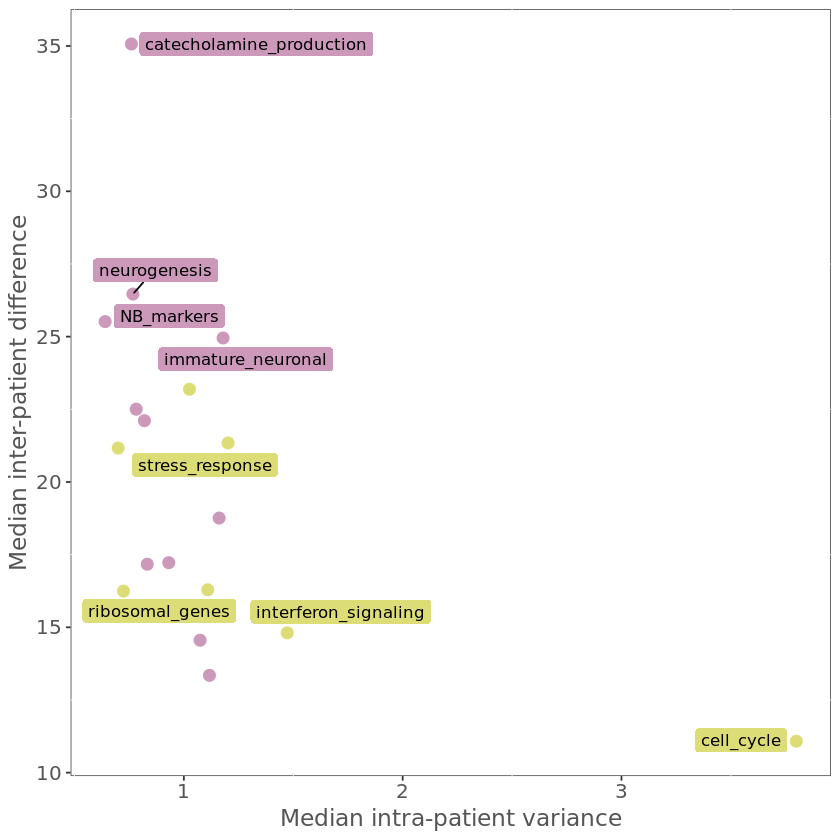

In [357]:

ploto <- ggplot(df_allStats, aes(x = median_var, y = median_diff, col = cat, fill = cat)) +
            geom_point(size = 3) +
            geom_label_repel(data = df_allStats[!is.na(df_allStats$catlabel),],aes(label = module), size = 3.5, label.size = 0.01, max.overlaps = 50, box.padding = 0.3, point.padding = 0, color = 'black', force = 20) +
            scale_color_manual(values = c('#DDDD77','#CC99BB')) +
            scale_fill_manual(values = c('#DDDD77','#CC99BB','#FFFFFF80')) +
            labs(x = 'Median intra-patient variance', y = 'Median inter-patient difference') +
            theme(legend.position="none") +
            mytheme_basic
ploto

#ggsave(plot = ploto, filename = paste0("pics/IntraPatVar_and_InterPatDiff_median_Jitter_VST_type_AUC_VAR_filt_",filt_type,"_treatFilt_",treat_filt,"_DIFF_type_",diff_type,"_filtAUCfiltered_",diff_exp_filt,"_treatFilt_",diff_treat_filt,"_manualLabelsOnly.png"), width = 7, height = 3.5, dpi = 500)



In [358]:

pdf(paste0("pics/IntraPatVar_and_InterPatDiff_median_Jitter_VST_type_AUC_VAR_filt_",filt_type,"_treatFilt_",treat_filt,"_DIFF_type_",diff_type,"_filtAUCfiltered_",diff_exp_filt,"_treatFilt_",diff_treat_filt,"_manualLabelsOnly_withLegend.pdf"), width = 7, height = 2.9)
        print(
        ggplot(df_allStats, aes(x = median_var, y = median_diff, col = cat, fill = cat)) +
                    geom_point(size = 3) +
                    geom_label_repel(data = df_allStats[!is.na(df_allStats$catlabel),],aes(label = module), size = 3.5, label.size = 0.01, max.overlaps = 50, box.padding = 0.3, point.padding = 0, color = 'black', force = 20) +
                    scale_color_manual(values = c('#DDDD77','#CC99BB')) +
                    scale_fill_manual(values = c('#DDDD77','#CC99BB','#FFFFFF80')) +
                    labs(x = 'Median intra-patient variance', y = 'Median inter-patient difference') +
                    mytheme_basic

        )
dev.off()    


pdf(paste0("pics/IntraPatVar_and_InterPatDiff_median_Jitter_VST_type_AUC_VAR_filt_",filt_type,"_treatFilt_",treat_filt,"_DIFF_type_",diff_type,"_filtAUCfiltered_",diff_exp_filt,"_treatFilt_",diff_treat_filt,"_manualLabelsOnly.pdf"), width = 5, height = 3.2)
        print(
        ggplot(df_allStats, aes(x = median_var, y = median_diff, col = cat, fill = cat)) +
                    geom_point(size = 3) +
                    geom_label_repel(data = df_allStats[!is.na(df_allStats$catlabel),],aes(label = module), size = 3.5, label.size = 0.01, max.overlaps = 50, box.padding = 0.3, point.padding = 0, color = 'black', force = 20) +
                    scale_color_manual(values = c('#DDDD77','#CC99BB')) +
                    scale_fill_manual(values = c('#DDDD77','#CC99BB','#FFFFFF80')) +
                    labs(x = 'Median intra-patient variance', y = 'Median inter-patient difference') +
                    theme(legend.position="none") +
                    mytheme_basic

        )
dev.off()   
dev.off()    

dev.off()    
dev.off()    


png 
  2

png 
  2

null device 
          1

null device 
          1

null device 
          1